# Vaizdų atpažinimas: tikros ir DI sugeneruotos naujienų nuotraukos

Uždavinys: nustatyti, ar naujienų nuotrauka tikra, ar sugeneruota dirbtinio intelekto. Tai nauja netikrų naujienų forma: sugeneruotos „naujienų nuotraukos“, kurios atrodo kaip tikros.

Duomenys: **MiRAGeNews** (Huang et al., EMNLP Findings 2024). Tikros nuotraukos paimtos iš naujienų leidėjų, o netikros sugeneruotos difuzijos modeliais pagal naujienų antraštes. Naudojamas **MobileNetV2**, iš anksto išmokytas su ImageNet nuotraukomis (perkeliamasis mokymas), ir palyginami du būdai paduoti vaizdą tinklui:

1. **Sumažintas vaizdas**: visas vaizdas suspaudžiamas iki 224 × 224 pikselių (įprastas būdas).
2. **Originali raiška**: mokoma su atsitiktinėmis 224 × 224 dalimis originaliu dydžiu, o tikrinama su visu vaizdu originaliu dydžiu. Taip išlieka smulkūs pikselių pėdsakai, kuriuos palieka generatorius ir kuriuos sumažinimas ištrina.

Keras veikia su PyTorch backend, todėl mokoma su GPU.

In [1]:
import os, io, time, warnings
os.environ["KERAS_BACKEND"] = "torch"  # turi buti nustatyta pries importuojant keras
import numpy as np, pandas as pd, matplotlib.pyplot as plt, keras
from pathlib import Path
from PIL import Image, ImageFilter
from keras import layers
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

DATA = Path("../data/mirage_news")
FIG = Path("../report/figures"); FIG.mkdir(parents=True, exist_ok=True)
MODELS = Path("../models")
SIZE = 224
MODES = {"resize": "resized to 224", "native": "native resolution"}
warnings.filterwarnings("ignore", message="`input_shape` is undefined")  # ImageNet svoriai tinka bet kokiam dydziui, ispejimas nesvarbus

## 1. Duomenys
Mokymui 10 000 vaizdų, validacijai 2 500, o trys testo rinkiniai po 500. Kiekviename rinkinyje pusė vaizdų tikri (`label` 0), pusė sugeneruoti (`label` 1).

| Rinkinys | Tikros nuotraukos | Sugeneruoti vaizdai | Ar matyta mokant |
|---|---|---|---|
| train, validation | The New York Times | Midjourney | |
| test1 | The New York Times | Midjourney | tas pats šaltinis |
| test4 | BBC | Stable Diffusion XL | kitas leidėjas ir generatorius |
| test5 | CNN | Stable Diffusion XL | kitas leidėjas ir generatorius |

Du testo rinkiniai su DALL·E vaizdais neatsisiųsti, nes kitą generatorių jau tikrina test4 ir test5. Vaizdai laikomi atmintyje kaip JPEG baitai (mokymo rinkinys apie 650 MB) ir išskleidžiami tik paduodant tinklui, nes išskleisti 10 000 vaizdų užimtų kelis GB.

In [2]:
def load(name):
    df = pd.read_parquet(DATA / f"{name}-00000-of-00001.parquet", columns=["image", "label"])
    return [d["bytes"] for d in df["image"]], df["label"].to_numpy()

def open_rgb(b):
    return Image.open(io.BytesIO(b)).convert("RGB")  # keli vaizdai PNG arba nespalvoti

train_x, train_y = load("train")
sets = {"validation": load("validation"), "test1 NYT / Midjourney": load("test1_nyt_mj"),
        "test4 BBC / SDXL": load("test4_bbc_sdxl"), "test5 CNN / SDXL": load("test5_cnn_sdxl")}

Prieš mokant patikrinta, kuo tikri ir netikri vaizdai skiriasi ne turiniu, o failu. Jei toks skirtumas yra, tinklas gali išmokti jį, o ne generatoriaus požymius.

In [3]:
def jpeg_table(b):  # JPEG kvantavimo lenteles vidurkis: kuo didesnis, tuo stipriau suspausta
    im = Image.open(io.BytesIO(b))
    return np.mean(im.quantization[0]) if im.format == "JPEG" else np.nan

rows = {}
for name, (x, y) in {"train": (train_x, train_y), **sets}.items():
    q = np.array([jpeg_table(b) for b in x])
    size = pd.Series([Image.open(io.BytesIO(b)).size for b in x])  # skaito tik antraste, ne visa vaizda
    rows[name] = {"images": len(y), "fake share": y.mean(),
                  "real: JPEG table mean (median)": np.nanmedian(q[y == 0]), "fake: JPEG table mean (median)": np.nanmedian(q[y == 1]),
                  "fake: distinct JPEG tables": len(np.unique(q[y == 1])),
                  "real: most common size": size[y == 0].mode()[0], "fake: most common size": size[y == 1].mode()[0],
                  "side under 224 px": int(size.map(min).lt(SIZE).sum())}
pd.DataFrame(rows).T

,images,fake share,real: JPEG table mean (median),fake: JPEG table mean (median),fake: distinct JPEG tables,real: most common size,fake: most common size,side under 224 px
train,10000,0.5,44.8125,29.03125,1,"(600, 400)","(600, 400)",1024
validation,2500,0.5,44.8125,29.03125,1,"(600, 400)","(600, 400)",154
test1 NYT / Midjourney,500,0.5,44.8125,29.03125,1,"(600, 330)","(600, 330)",0
test4 BBC / SDXL,500,0.5,23.078125,29.03125,1,"(1024, 576)","(1024, 1024)",0
test5 CNN / SDXL,500,0.5,29.03125,29.03125,1,"(1100, 619)","(1024, 1024)",0


Pastebėti du dalykai:

- **Visi sugeneruoti vaizdai išsaugoti su ta pačia JPEG kvantavimo lentele**, o tikros nuotraukos turi kiekvieno leidėjo savo suspaudimą (dažniausiai stipresnį). Tinklas galėtų išmokti „šis JPEG nustatymas reiškia netikrą“ vietoj generatoriaus požymių. Todėl mokant dalis vaizdų atsitiktinai suspaudžiama iš naujo (2 skyrius).
- Mokymo ir test1 rinkiniuose sugeneruoti vaizdai sumažinti iki tokio pat dydžio kaip tikros nuotraukos, todėl dydis klasių neišduoda. Test4 ir test5 rinkiniuose visi sugeneruoti vaizdai yra 1024 × 1024 kvadratai, o tikros nuotraukos 16:9. Suspaudus viską į 224 × 224, tikros nuotraukos būtų suplotos, o sugeneruoti vaizdai ne. Tai dar viena priežastis tikrinti originaliu dydžiu.

Mokymo vaizdų pavyzdžiai (viršuje tikros nuotraukos, apačioje sugeneruoti vaizdai):

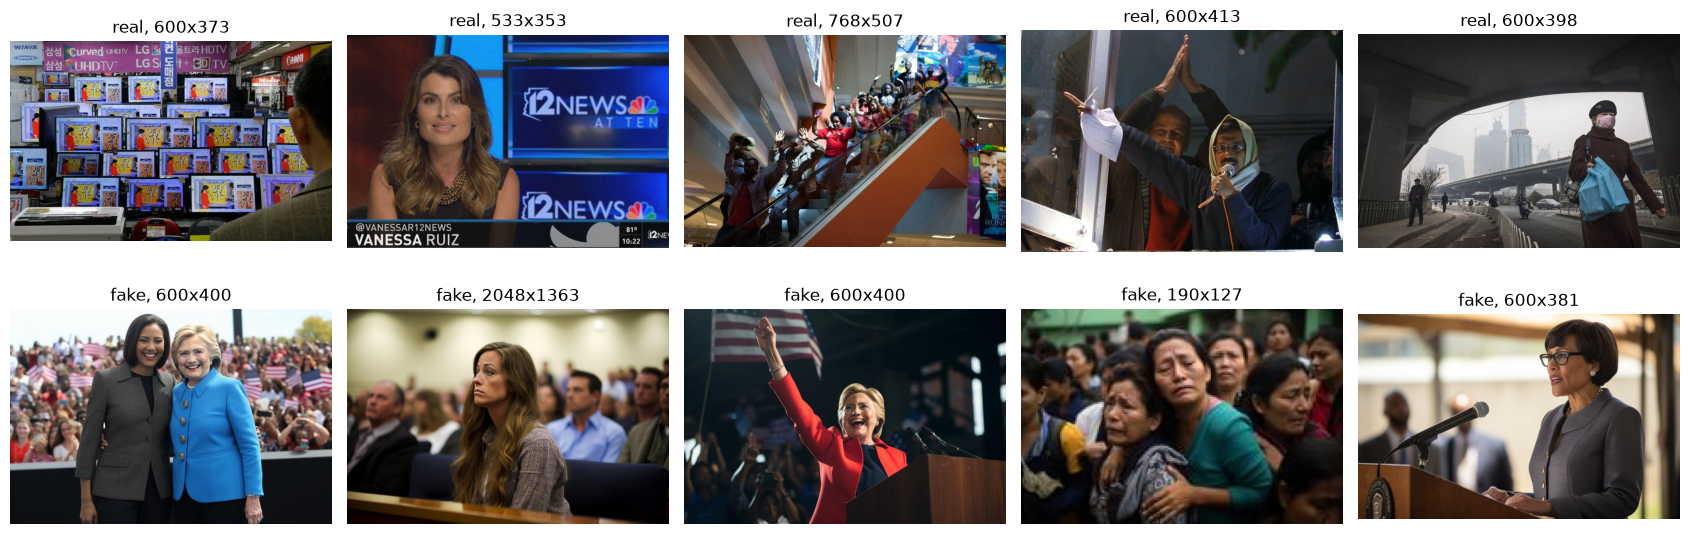

In [4]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for row, label in zip(axes, (0, 1)):
    for ax, j in zip(row, rng.choice(np.flatnonzero(train_y == label), 5, replace=False)):
        im = open_rgb(train_x[j])
        ax.imshow(im); ax.set_title(f"{('real', 'fake')[label]}, {im.width}x{im.height}"); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "img_examples.png", dpi=110); plt.show()

## 2. Duomenų paruošimas

Abu modeliai gauna tą patį 224 × 224 vaizdą, tik skirtingai paruoštą:

- **Sumažintas vaizdas:** visas vaizdas suspaudžiamas iki 224 × 224, nepaisant proporcijų.
- **Originali raiška:** mokant iš vaizdo iškerpama atsitiktinė 224 × 224 dalis be jokio mastelio keitimo. Tikrinant tinklui paduodamas visas vaizdas originaliu dydžiu: MobileNetV2 sudarytas tik iš konvoliucijų, o gale imamas vidurkis per visą vaizdą, todėl tinka bet koks dydis. Vaizdai, kurių kraštinė mažesnė nei 224 pikseliai, papildomi juodu kraštu, o ne didinami, kad pikseliai nebūtų suglodinti.

Mokymo vaizdai keičiami atsitiktinai (augmentacija), kad tinklas mokytųsi vaizdo savybių, o ne konkrečių vaizdų:

| Pakeitimas | Tikimybė | Kodėl |
|---|---|---|
| Apvertimas horizontaliai | 50 % | veidrodinis vaizdas nekeičia, ar jis tikras |
| Lengvas suliejimas (σ 0,1-1) | 20 % | kad tinklas nepasikliautų vien ryškiausiais pikselių pėdsakais |
| Pakartotinis JPEG suspaudimas (kokybė 60-100) | 50 % | panaikina vienodo JPEG nustatymo užuominą; socialiniai tinklai nuotraukas irgi suspaudžia iš naujo |

Priartinimas ir pasukimas nenaudojami: jie perskaičiuoja pikselius ir suglodina būtent tą triukšmą, kurį tinklas turi pamatyti. Validacijos ir testo vaizdai nekeičiami.

In [5]:
def pad(im):  # mazus vaizdus papildom juodu krastu, kad nereiktu didinti
    if im.width >= SIZE and im.height >= SIZE:
        return im
    out = Image.new("RGB", (max(im.width, SIZE), max(im.height, SIZE)))
    out.paste(im)
    return out

def augment(im, rng):
    if rng.random() < 0.5:
        im = im.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
    if rng.random() < 0.2:
        im = im.filter(ImageFilter.GaussianBlur(rng.uniform(0.1, 1.0)))
    if rng.random() < 0.5:  # visi netikri saugoti vienodu JPEG nustatymu, todel suspaudziam is naujo atsitiktine kokybe
        buf = io.BytesIO()
        im.save(buf, "JPEG", quality=int(rng.integers(60, 101)))
        im = Image.open(buf).convert("RGB")
    return im

class Images(keras.utils.PyDataset):
    def __init__(self, x, y, mode, train=False, batch_size=32):
        super().__init__(workers=4)  # vaizdus isskleidzia 4 gijos, kol GPU mokosi
        self.x, self.y, self.mode, self.train, self.batch_size = x, y, mode, train, batch_size
        self.epoch = 0
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.x) / self.batch_size))

    def on_epoch_end(self):
        self.epoch += 1
        self.order = np.random.default_rng(self.epoch).permutation(len(self.x)) if self.train else np.arange(len(self.x))

    def prepare(self, im, rng):
        if self.mode == "resize":
            im = im.resize((SIZE, SIZE), Image.BILINEAR)
        else:
            im = pad(im)
            if self.train:  # atsitiktine 224x224 dalis, pikseliai nekeiciami
                left, top = rng.integers(0, im.width - SIZE + 1), rng.integers(0, im.height - SIZE + 1)
                im = im.crop((left, top, left + SIZE, top + SIZE))
        if self.train:
            im = augment(im, rng)
        return np.asarray(im, dtype="float32")

    def __getitem__(self, i):
        rng = np.random.default_rng([self.epoch, i])  # ta pati paketo atsitiktinybe nepriklausomai nuo giju eiles
        idx = self.order[i * self.batch_size:(i + 1) * self.batch_size]
        images = np.stack([self.prepare(open_rgb(self.x[j]), rng) for j in idx])
        return images, self.y[idx, None].astype("float32")

def batches(x, y, mode, train=False):
    return Images(x, y, mode, train, batch_size=32 if mode == "resize" or train else 1)  # originalaus dydzio vaizdai skirtingu dydziu, todel po viena

Ką mato kiekvienas modelis. Raudonas kvadratas kairėje yra viena 224 × 224 dalis, kurią mato originalios raiškos modelis; viduryje tas pats vaizdas, sumažintas iki 224 × 224.

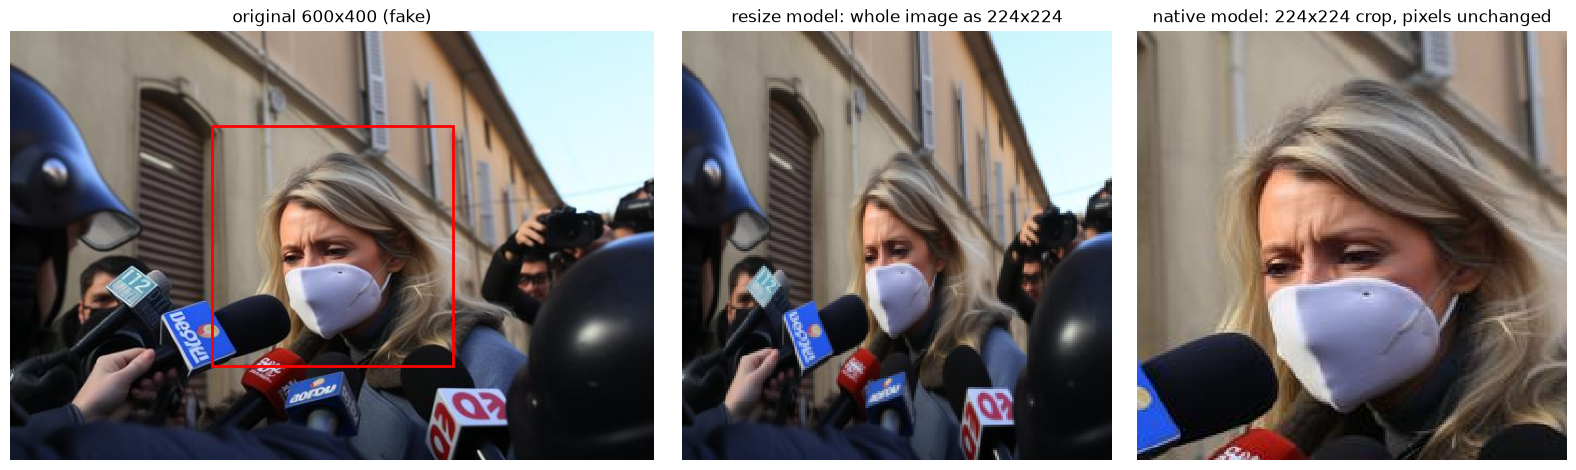

In [6]:
j = next(j for j in np.flatnonzero(train_y == 1) if Image.open(io.BytesIO(train_x[j])).size == (600, 400))
im = open_rgb(train_x[j])
left, top = (im.width - SIZE) // 2, (im.height - SIZE) // 2
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [im.width / im.height, 1, 1]})
axes[0].imshow(im); axes[0].add_patch(plt.Rectangle((left, top), SIZE, SIZE, fill=False, ec="red", lw=2))
axes[0].set_title(f"original {im.width}x{im.height} (fake)")
axes[1].imshow(im.resize((SIZE, SIZE), Image.BILINEAR), interpolation="nearest"); axes[1].set_title("resize model: whole image as 224x224")
axes[2].imshow(im.crop((left, top, left + SIZE, top + SIZE)), interpolation="nearest"); axes[2].set_title("native model: 224x224 crop, pixels unchanged")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "img_model_input.png", dpi=110, bbox_inches="tight"); plt.show()

## 3. Modelis

Abiejų modelių architektūra ta pati, skiriasi tik įvesties dydis (224 × 224 arba bet koks):

| Sluoksnis | Paskirtis |
|---|---|
| Įvestis | RGB vaizdas, pikseliai 0-255 |
| Rescaling | perskaičiuoja pikselius į intervalą nuo -1 iki 1, kokio tikisi MobileNetV2 |
| MobileNetV2 (ImageNet svoriai) | konvoliucinis tinklas, išmokytas atpažinti objektus 1,4 mln. ImageNet nuotraukų; iš vaizdo išskiria 1 280 požymių žemėlapių |
| GlobalAveragePooling2D | kiekvieno požymio vidurkis per visą vaizdą, todėl įvesties dydis gali būti bet koks |
| Dropout 0,3 | mokant atsitiktinai išjungia 30 % požymių, kad tinklas neįsimintų mokymo vaizdų |
| Dense 1, sigmoid | tikimybė, kad vaizdas sugeneruotas |

Mokoma dviem etapais:

1. MobileNetV2 užšaldytas, mokomas tik paskutinis sluoksnis. Adam, mokymosi greitis 1e-3, iki 10 epochų.
2. Atitirpdomi viršutiniai 30 MobileNetV2 sluoksnių ir mokoma toliau su 100 kartų mažesniu greičiu (1e-5), iki 10 epochų, kad ImageNet svoriai būtų tik pakoreguoti, o ne sugadinti.

Abiem etapais nuostolių funkcija yra binary cross-entropy, paketo dydis 32, o mokymas sustabdomas, kai validacijos accuracy 2 epochas nebekyla, ir grąžinami geriausi svoriai. BatchNorm sluoksniai visą laiką naudoja ImageNet statistiką. Originalios raiškos modelio validacija atliekama su visais vaizdais originaliu dydžiu.

In [7]:
def build(shape):
    base = keras.applications.MobileNetV2(input_shape=shape, include_top=False, weights="imagenet")
    base.trainable = False
    inputs = keras.Input(shape)
    x = layers.Rescaling(1 / 127.5, offset=-1)(inputs)
    x = base(x, training=False)  # BatchNorm lieka su ImageNet statistika ir atitirpdzius
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    return keras.Model(inputs, layers.Dense(1, activation="sigmoid")(x)), base

def train(mode):
    path, hist_path = MODELS / f"mobilenetv2_{mode}.keras", MODELS / f"mobilenetv2_{mode}_history.csv"
    if path.exists():
        return keras.saving.load_model(path, compile=False), pd.read_csv(hist_path)  # tik spejimams, optimizatoriaus nereikia
    keras.utils.set_random_seed(42)  # kad perleidus gautusi tie patys svoriai
    model, base = build((SIZE, SIZE, 3) if mode == "resize" else (None, None, 3))
    data, val = batches(train_x, train_y, mode, train=True), batches(*sets["validation"], mode)
    hist = []
    for stage, lr in [("frozen", 1e-3), ("fine-tuned", 1e-5)]:
        if stage == "fine-tuned":
            base.trainable = True
            for layer in base.layers[:-30]:  # atitirpdom tik virsutinius 30 sluoksniu
                layer.trainable = False
        model.compile(keras.optimizers.Adam(lr), "binary_crossentropy", metrics=["accuracy"])
        start = time.time()
        h = model.fit(data, validation_data=val, epochs=10, verbose=2,
                      callbacks=[keras.callbacks.EarlyStopping("val_accuracy", mode="max", patience=2, restore_best_weights=True)])
        hist.append(pd.DataFrame(h.history).assign(stage=stage, stage_minutes=(time.time() - start) / 60))
    model.save(path)
    hist = pd.concat(hist, ignore_index=True); hist.to_csv(hist_path, index=False)
    return model, hist

models, hists = {}, {}
for mode in MODES:
    models[mode], hists[mode] = train(mode)
models["native"].summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, None, None,     │     2,257,984 │
│ (Functional)                    │ 1280)                  │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,527,681 (5.83 MB)

 Non-trainable params: 731,584 (2.79 MB)

## 4. Mokymo eiga

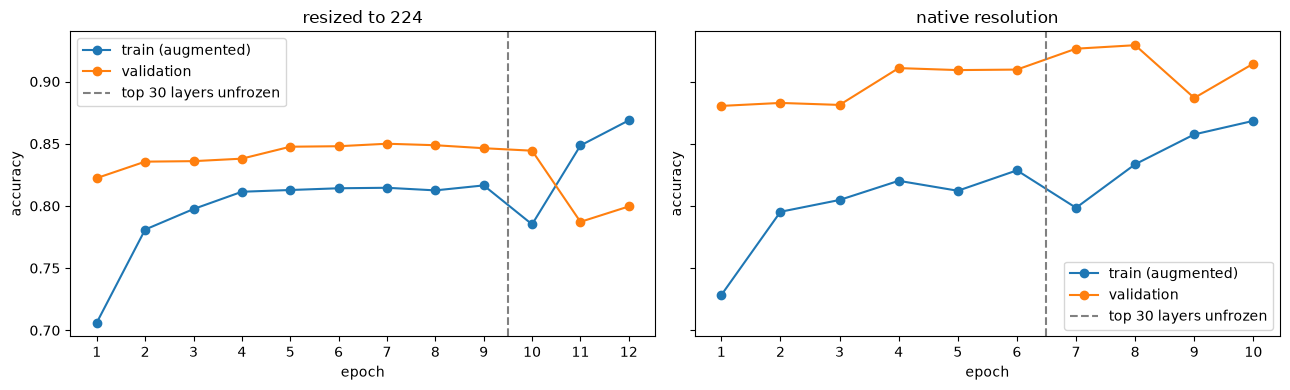

epochs  best_val_accuracy  minutes
model  stage                                         
resize frozen           9              0.850    6.136
       fine-tuned       3              0.844    2.029
native frozen           6              0.911   20.983
       fine-tuned       4              0.929   13.246

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (mode, hist) in zip(axes, hists.items()):
    epochs = np.arange(1, len(hist) + 1)
    ax.plot(epochs, hist["accuracy"], "o-", label="train (augmented)")
    ax.plot(epochs, hist["val_accuracy"], "o-", label="validation")
    ax.axvline((hist["stage"] == "frozen").sum() + 0.5, color="gray", ls="--", label="top 30 layers unfrozen")
    ax.set(title=MODES[mode], xlabel="epoch", ylabel="accuracy", xticks=epochs); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "img_history.png", dpi=120); plt.show()
pd.concat(hists, names=["model", "row"]).groupby(["model", "stage"], sort=False).agg(
    epochs=("accuracy", "size"), best_val_accuracy=("val_accuracy", "max"), minutes=("stage_minutes", "first")).round(3)

Sumažinto vaizdo modeliui atitirpdymas nepadėjo: jau po antros šio etapo epochos validacijos accuracy krito nuo 84,4 % iki 78,7 %, nors mokymo accuracy kilo, t. y. tinklas pradėjo įsiminti mokymo vaizdus. Grąžinti geriausi šio etapo svoriai (84,4 %), šiek tiek prastesni nei užšaldyto etapo 85,0 %. Originalios raiškos modeliui atitirpdymas pakėlė validacijos accuracy nuo 91,1 % iki 92,9 %.

Validacijos accuracy didesnis nei mokymo, nes mokymo vaizdai keičiami (suliejami, suspaudžiami iš naujo), o validacijos ne. Originalios raiškos modelis mokosi apie 4 kartus lėčiau, nes kiekvieną epochą 2 500 validacijos vaizdų tikrina po vieną visu dydžiu.

## 5. Rezultatai
Kiekvienam rinkiniui gaunama tikimybė, kad vaizdas sugeneruotas; nuo 0,5 laikoma „fake“. Tikimybės išsaugomos `models/mirage_predictions.csv`, kad perleidus nereiktų skaičiuoti iš naujo. Visi rinkiniai pusiau tikri ir pusiau sugeneruoti, todėl accuracy yra sąžiningas įvertis. Precision ir recall skaičiuojami sugeneruotiems vaizdams: recall rodo, kokią dalį sugeneruotų vaizdų modelis pagavo, o „real kept“ rodo, kokią dalį tikrų nuotraukų jis teisingai paliko tikromis.

In [9]:
PRED = MODELS / "mirage_predictions.csv"
if PRED.exists():
    preds = pd.read_csv(PRED)
else:
    preds = pd.concat([pd.DataFrame({"split": name, "model": mode, "image": np.arange(len(y)), "label": y,
                                     "p_fake": models[mode].predict(batches(x, y, mode), verbose=0)[:, 0]})
                       for name, (x, y) in sets.items() for mode in MODES])
    preds.to_csv(PRED, index=False)

def scores(g):
    y, p = g["label"], (g["p_fake"] >= 0.5).astype(int)
    return pd.Series({"accuracy": accuracy_score(y, p), "precision": precision_score(y, p, zero_division=0),
                      "recall (fake caught)": recall_score(y, p), "real kept": recall_score(1 - y, 1 - p), "F1": f1_score(y, p)})

table = preds.groupby(["split", "model"], sort=False).apply(scores).round(3)
table

accuracy  precision  recall (fake caught)  \
split                  model                                               
validation             resize     0.844      0.780                 0.958   
                       native     0.929      0.892                 0.976   
test1 NYT / Midjourney resize     0.846      0.787                 0.948   
                       native     0.904      0.848                 0.984   
test4 BBC / SDXL       resize     0.612      0.610                 0.620   
                       native     0.652      0.606                 0.872   
test5 CNN / SDXL       resize     0.642      0.638                 0.656   
                       native     0.726      0.679                 0.856   

                               real kept     F1  
split                  model                     
validation             resize      0.730  0.860  
                       native      0.882  0.932  
test1 NYT / Midjourney resize      0.744  0.860  
                       native      0.824  0.911  
test4 BBC / SDXL       resize      0.604  0.615  
                       native      0.432  0.715  
test5 CNN / SDXL       resize      0.628  0.647  
                       native      0.596  0.758

Accuracy pagal leidėją ir generatorių:

In [10]:
table["accuracy"].unstack("model")[list(MODES)].rename(columns=MODES)

model,resized to 224,native resolution
split,,
validation,0.844,0.929
test1 NYT / Midjourney,0.846,0.904
test4 BBC / SDXL,0.612,0.652
test5 CNN / SDXL,0.642,0.726


Klaidų matricos test1 rinkiniui (tas pats šaltinis kaip mokymo):

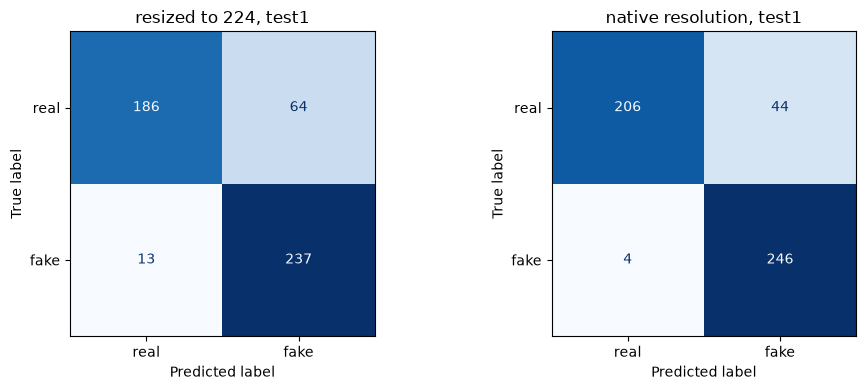

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, mode in zip(axes, MODES):
    g = preds[(preds["split"] == "test1 NYT / Midjourney") & (preds["model"] == mode)]
    ConfusionMatrixDisplay.from_predictions(g["label"], (g["p_fake"] >= 0.5).astype(int), display_labels=["real", "fake"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{MODES[mode]}, test1")
plt.tight_layout(); plt.savefig(FIG / "img_confusion.png", dpi=120); plt.show()

**Originalios raiškos modelis geresnis visuose rinkiniuose**: test1 90,4 % prieš 84,6 %, test4 65,2 % prieš 61,2 %, test5 72,6 % prieš 64,2 %. Taigi smulkios pikselių detalės, kurias sumažinimas ištrina, iš tikrųjų padeda atskirti sugeneruotus vaizdus.

Tame pačiame šaltinyje (test1) abu modeliai pagauna beveik visus sugeneruotus vaizdus (98,4 % ir 94,8 %), o klysta daugiausia su tikromis nuotraukomis: originalios raiškos modelis 44 iš 250 tikrų NYT nuotraukų palaiko sugeneruotomis, sumažinto vaizdo modelis 64.

Kitų leidėjų ir kito generatoriaus rinkiniuose accuracy nukrenta 18-25 punktais. Originalios raiškos modelis SDXL vaizdų vis dar pagauna daug (87,2 % ir 85,6 %), bet tikrų BBC ir CNN nuotraukų teisingai palieka tik 43,2 % ir 59,6 %. Sumažinto vaizdo modelis test4 ir test5 rinkiniuose abiejose klasėse teisus tik apie 60 % atvejų.

## 6. Klaidos
Pasirinkto modelio (didesnis validacijos accuracy) klaidos, kuriose jis buvo labiausiai įsitikinęs: kiekviename testo rinkinyje po dvi tikras nuotraukas, palaikytas sugeneruotomis, ir po du sugeneruotus vaizdus, palaikytus tikrais.

model: native resolution, errors per test set: {'test1 NYT / Midjourney': 48, 'test4 BBC / SDXL': 174, 'test5 CNN / SDXL': 137}


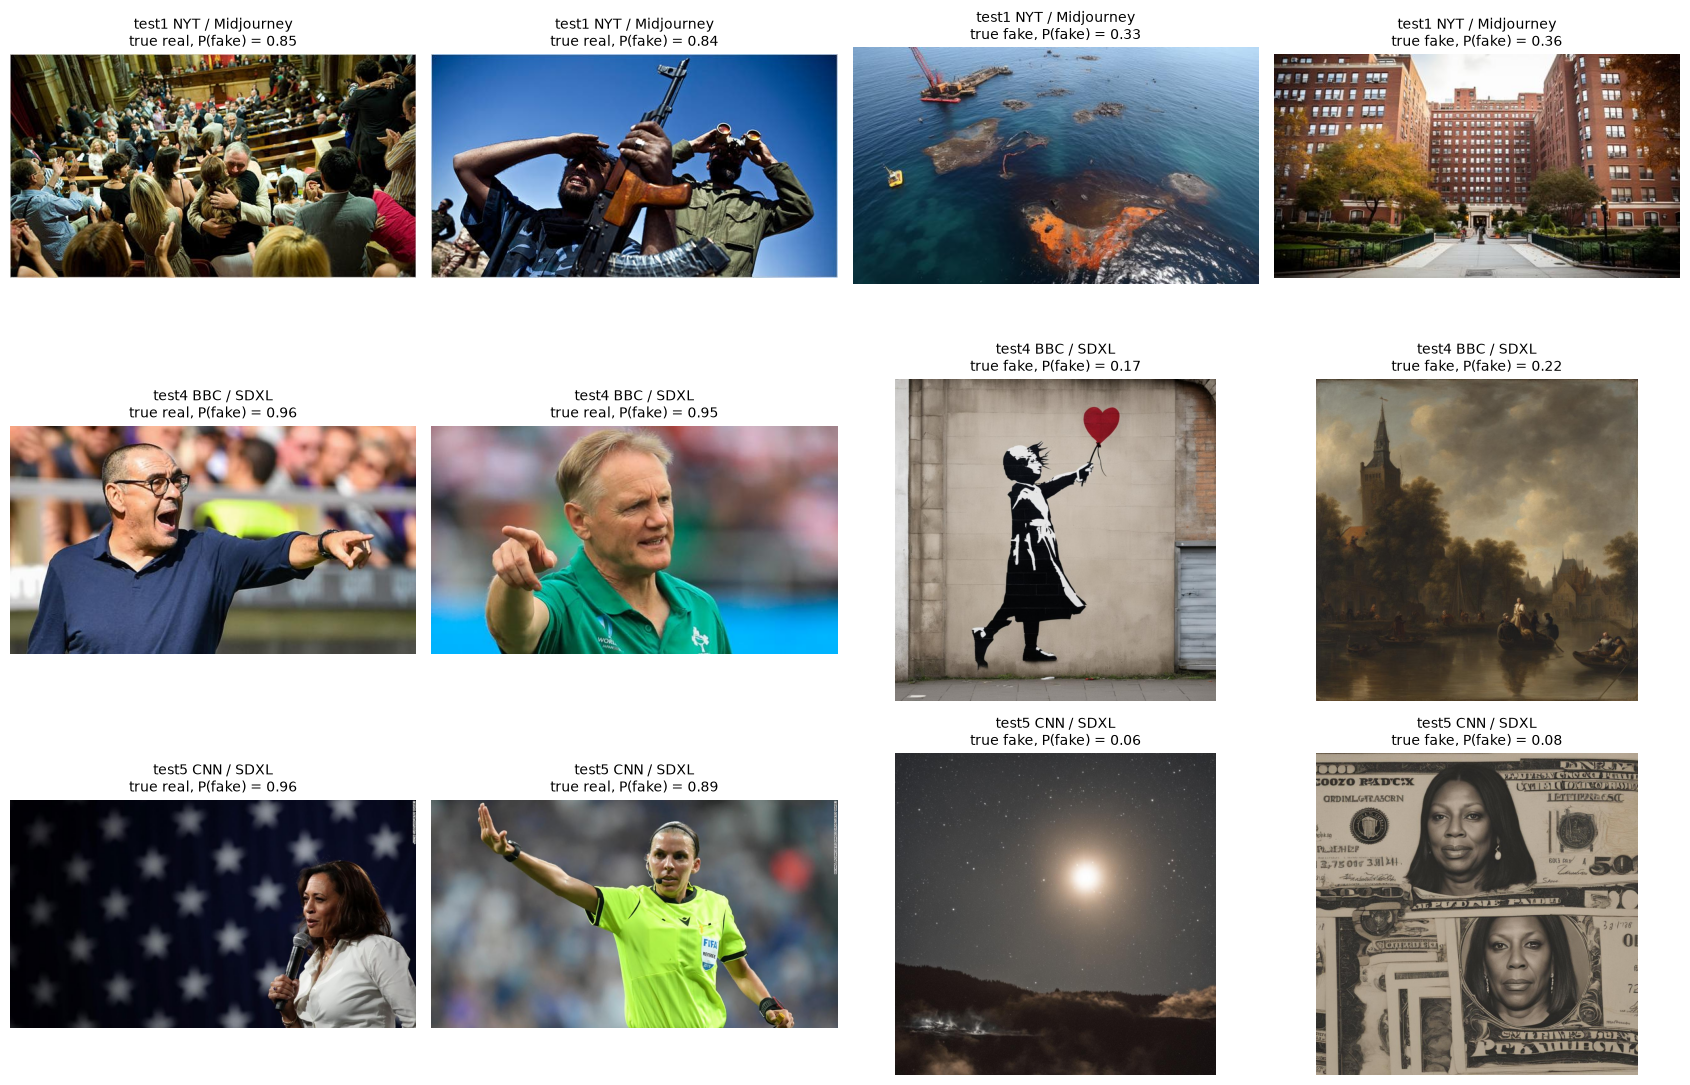

In [12]:
best = table.loc["validation", "accuracy"].idxmax()
wrong = preds[(preds["model"] == best) & (preds["split"] != "validation") & ((preds["p_fake"] >= 0.5) != preds["label"])]
wrong = wrong.assign(sureness=(wrong["p_fake"] - 0.5).abs()).sort_values("sureness", ascending=False)
picked = wrong.groupby(["split", "label"], sort=False).head(2).sort_values(["split", "label"])
print(f"model: {MODES[best]}, errors per test set:", wrong.groupby("split").size().to_dict())

fig, axes = plt.subplots(3, 4, figsize=(17, 11))
for ax, (_, r) in zip(axes.flat, picked.iterrows()):
    ax.imshow(open_rgb(sets[r["split"]][0][r["image"]]))
    ax.set_title(f"{r['split']}\ntrue {('real', 'fake')[r['label']]}, P(fake) = {r['p_fake']:.2f}", fontsize=10); ax.axis("off")
for ax in axes.flat[len(picked):]: ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "img_errors.png", dpi=110); plt.show()

### Dažniausios klaidos

1. **Kitas leidėjas ir kitas generatorius.** Test1 rinkinyje modelis suklysta 48 kartus iš 500, test4 - 174, test5 - 137. Daugiausia naujų klaidų yra tikros BBC ir CNN nuotraukos, palaikytos sugeneruotomis (142 ir 101), o ne praleisti SDXL vaizdai (32 ir 36). Modelis išmoko atskirti NYT nuotraukas nuo Midjourney vaizdų, o ne „tikrą“ nuo „sugeneruoto“ apskritai, todėl nuotrauka, nepanaši į NYT stilių, dažnai tampa „fake“.
2. **Išblizgintos profesionalios nuotraukos.** Labiausiai įsitikinęs modelis klysta su tikromis sporto ir portretų nuotraukomis: ryškios spalvos, švarus apšvietimas, stipriai išlietas fonas (P(fake) 0,89-0,96). Būtent taip atrodo Midjourney vaizdai mokymo duomenyse. Test1 rinkinyje sugeneruotomis palaikytos tikros nuotraukos su ryškia blykste ir sodriu dangumi.
3. **Sugeneruoti vaizdai, nepanašūs į nuotraukas.** Tikrais palaikyti SDXL vaizdai yra gatvės piešinys, paveikslas aliejiniais dažais, naktinis dangus ir banknotų koliažas (P(fake) 0,06-0,22). Mokymo duomenų Midjourney vaizdai daugiausia panašūs į naujienų nuotraukas, todėl kitokio stiliaus sugeneruoto vaizdo modelis neatpažįsta.
4. **Paprastos sugeneruotos scenos.** Test1 rinkinyje tikrais palaikyti sugeneruoti jūros vaizdas iš viršaus ir gyvenamasis namas (P(fake) 0,33-0,36): mažai žmonių ir smulkių detalių, kuriose modelis galėtų pastebėti generatoriaus pėdsakus.
5. **Sumažinimas iki 224 × 224.** Sumažinto vaizdo modelis test1 rinkinyje suklysta 77 kartus, originalios raiškos 48. Sumažinant dingsta smulkūs generatoriaus pėdsakai, todėl tinklui lieka tik bendras vaizdo stilius.

## 7. Išvados
Originalios raiškos MobileNetV2 atpažįsta Midjourney vaizdus tarp NYT nuotraukų 90,4 % tikslumu, 5,8 punkto geriau nei tas pats tinklas su sumažintais vaizdais. Su kitais leidėjais ir SDXL generatoriumi tikslumas nukrenta iki 65-73 %, daugiausia dėl tikrų nuotraukų, palaikytų sugeneruotomis. Toks modelis tinka tik tam generatoriui ir tokioms nuotraukoms, su kuriomis mokytas; norint atpažinti sugeneruotus vaizdus apskritai, mokymo duomenyse reikėtų kelių generatorių ir kelių leidėjų nuotraukų.